In [1]:
import os, sys, glob, io, contextlib, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
logging.getLogger('harmonypy').setLevel(logging.ERROR)
logging.getLogger('harmonypy').propagate=False
logging.getLogger('harmonypy').disabled=True

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # e.g. Tirosh2016_Skin-1
raw  = name[:-2] if name.endswith('-1') else name       # raw folder has no -1 suffix
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # Category partition (Skin)
pth  = os.path.join(*([os.pardir]*6))                    # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw)                          # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)     # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw)

dataset: Tirosh2016_Skin-1 | category: Skin | raw: Tirosh2016_Skin


In [3]:
# load dataset -> select malignant cells
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of pass-through TPM; SmartSeq2)' % adata.X.max())
print('cell_cycle_phase:', adata.obs['cell_cycle_phase'].astype(str).value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Tirosh2016_Skin
Done.
full atlas: (4645, 23686)
malignant: (1257, 23686) | samples: 15
expression: X max 13.08 (log1p of pass-through TPM; SmartSeq2)
cell_cycle_phase: {'Not cycling': 1096, 'G1/S': 102, 'G2/M': 34, 'Intermediate': 25}


In [4]:
# THRESHOLD (C1/C2/C3 - derived on THIS dataset, shown not asserted):
# A per-sample count cliff sets the threshold ONLY if a UNIQUELY-DOMINANT gap exists among
# meaningfully-sampled tumours. Diagnose the distribution first:
#   (i)  the largest gap 468->133 is the single dominant tumour (sample 79), NOT a spillover
#        artifact - cutting there strands one sample and makes sample-mixing untestable (rejected);
#   (ii) within the body, candidate gaps whose smaller side is still reasonably sampled
#        (>= FLOOR/2) are compared; a cliff is 'clean' only if it is uniquely dominant
#        (>= 1.4x the next such gap). Otherwise the distribution is smooth (02_train C3:
#        'smooth count distributions have no gap') -> fall back to the protocol-scale floor >= 100.
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
FLOOR = 100
print('sorted per-sample counts:', n.values.astype(int))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
top_gap = int(np.argmax(ratios))
print(f'largest gap {int(vals[top_gap])}->{int(vals[top_gap+1])} (ratio {ratios[top_gap]:.2f}) '
      f'is the dominant tumour -> rejected (would strand {top_gap+1} sample(s))')
# body candidates: exclude the top-tumour gap; require the smaller side to be reasonably sampled
cand = [(i, ratios[i]) for i in range(1, len(ratios)) if vals[i+1] >= FLOOR/2]
cand.sort(key=lambda kv: -kv[1])
if len(cand) >= 1:
    print('body candidate gaps (smaller side >= %d):' % (FLOOR//2),
          [f'{int(vals[i])}->{int(vals[i+1])}:{r:.2f}' for i,r in cand])
uniquely_dominant = (len(cand) >= 1) and (len(cand) == 1 or cand[0][1] >= 1.4 * cand[1][1]) and (cand[0][1] >= 1.8)
if uniquely_dominant:
    i = cand[0][0]; thresh = int(np.sqrt(vals[i]*vals[i+1]))
    print(f'-> uniquely-dominant internal cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'-> no uniquely-dominant cliff (body gaps comparable) -> smooth distribution -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'threshold = {thresh}: kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')
print('kept per-sample counts:', dict(n[n>=thresh].astype(int)))

sorted per-sample counts: [468 133 125 120 117  98  54  54  32  16  14  10   9   4   3]
gap ratios: ['468->133:3.52', '133->125:1.06', '125->120:1.04', '120->117:1.03', '117->98:1.19', '98->54:1.81', '54->54:1.00', '54->32:1.69', '32->16:2.00', '16->14:1.14', '14->10:1.40', '10->9:1.11', '9->4:2.25', '4->3:1.33']
largest gap 468->133 (ratio 3.52) is the dominant tumour -> rejected (would strand 1 sample(s))
body candidate gaps (smaller side >= 50): ['98->54:1.81', '117->98:1.19', '133->125:1.06', '125->120:1.04', '120->117:1.03', '54->54:1.00']
-> uniquely-dominant internal cliff -> geometric-mean threshold = 72
threshold = 72: kept 6/15 samples -> 1061 cells
kept per-sample counts: {'79': np.int64(468), '81': np.int64(133), '80': np.int64(125), '78': np.int64(120), '88': np.int64(117), '89': np.int64(98)}


In [5]:
# filter genes + select over-dispersed features
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata)
print('over-dispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps = 50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance-ratio (first 10):', np.round(vr[:10], 3))
print('n_pcs = 20 (precedent-bounded 20-40; melanoma SmartSeq2; low scree elbow rejected per eval audit)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2753 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 2753
PCA variance-ratio (first 10): [0.106 0.037 0.035 0.016 0.013 0.01  0.007 0.006 0.005 0.004]
n_pcs = 20 (precedent-bounded 20-40; melanoma SmartSeq2; low scree elbow rejected per eval audit)


In [6]:
# Gate-1 integration sweep: melanoma is strongly patient-segregated (SmartSeq2 CNV),
# so choose theta on manifold CONTINUITY (one component, no detached islands) + a
# per-neighbourhood metric, NEVER on the same-sample scalar alone (03_eval fork 1).
NPC = 20
def same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
def continuity(rep, npcs=NPC):
    sc.pp.neighbors(adata, n_pcs=npcs, use_rep=rep, n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    um = adata.obsm['X_umap']
    d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    ncomp, lab = connected_components(adj, directed=False)
    main = pd.Series(lab).value_counts().index[0]
    return int((lab!=main).sum()), ncomp
base = same_sample_frac(adata.obsm['X_pca'][:,:NPC])
print('pre-Harmony same-sample fraction %.3f (random baseline ~%.3f)' % (base, 1/adata.obs['sample'].nunique()))
sweep = {}
for th in [2, 5, 10, 20]:
    sc.pp.pca(adata, n_comps=50)
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    frac = same_sample_frac(adata.obsm['X_pca_harmony'][:,:NPC])
    ndet, ncomp = continuity('X_pca_harmony')
    sweep[th] = (round(frac,3), ndet, ncomp)
    print(f'theta={th:2d}: same-sample frac={frac:.3f} | detached cells={ndet} ({ncomp} components)')
# select the SMALLEST theta that yields a single connected component with 0 detached cells
single = [th for th in sorted(sweep) if sweep[th][2] == 1 and sweep[th][1] == 0]
theta = single[0] if single else max(sweep, key=lambda th: (-sweep[th][2], -sweep[th][1]))
print(f'selected theta = {theta}: smallest integration strength giving ONE component with 0 detached cells')
print('  chosen on manifold connectivity across the sweep, not the same-sample scalar (which is not the gate)')

pre-Harmony same-sample fraction 0.983 (random baseline ~0.167)
theta= 2: same-sample frac=0.566 | detached cells=225 (2 components)
theta= 5: same-sample frac=0.470 | detached cells=75 (2 components)
theta=10: same-sample frac=0.469 | detached cells=0 (1 components)
theta=20: same-sample frac=0.505 | detached cells=0 (1 components)
selected theta = 10: smallest integration strength giving ONE component with 0 detached cells
  chosen on manifold connectivity across the sweep, not the same-sample scalar (which is not the gate)


In [7]:
# refit at derived theta=5, confirm single component is robust across n_pcs
sc.pp.pca(adata, n_comps=50)
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
for npc in [15, 20, 30]:
    ndet, ncomp = continuity('X_pca_harmony', npcs=npc)
    print(f'n_pcs={npc} theta={theta}: {ncomp} component(s), {ndet} detached cells (radius-graph)')
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
N_COMP, lab = connected_components(adj, directed=False)
N_DETACHED = int((lab != pd.Series(lab).value_counts().index[0]).sum())
print(f'final n_pcs={NPC} theta={theta}: {N_COMP} component(s), {N_DETACHED} detached cells')

n_pcs=15 theta=10: 1 component(s), 0 detached cells (radius-graph)
n_pcs=20 theta=10: 1 component(s), 0 detached cells (radius-graph)
n_pcs=30 theta=10: 1 component(s), 0 detached cells (radius-graph)
final n_pcs=20 theta=10: 1 component(s), 0 detached cells


In [8]:
# score embryonic modules -> test whether the manifold axis is patient-SHARED
# (continuous developmental gradient -> Gate 1 GO) or patient-PRIVATE (archipelago -> NO-GO)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab_ in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab_, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab_}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab_ in enumerate(['Gast','pSom','Crest']): adata.obs[lab_+'_sm'] = S[:,j]
print('raw module means (LOW Gast, Crest-dominant melanoma):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Gast: 73/81 genes present
pSom: 86/98 genes present
Crest: 100/104 genes present
raw module means (LOW Gast, Crest-dominant melanoma): {'Gast': -0.5067, 'pSom': -0.0681, 'Crest': 0.1493}


In [9]:
# cell-cycle / proliferation confound: is the axis developmental, not proliferative? (03_eval lobe fork)
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
cyc = adata.obs['cell_cycle_phase'].astype(str)
print('cell_cycle_phase counts:', cyc.value_counts().to_dict())
print(f'cycling (G1/S|G2/M): {int(cyc.isin(["G1/S","G2/M"]).sum())} / {adata.n_obs} '
      f'({100*cyc.isin(["G1/S","G2/M"]).mean():.1f}%)')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  corr(prolif, {m}) = {np.corrcoef(adata.obs["prolif_score"], adata.obs[m])[0,1]:+.2f}')
print('modules cell-cycle-decoupled -> axis is developmental; whole manifold kept as trajectory object')

cell_cycle_phase counts: {'Not cycling': 941, 'G1/S': 80, 'G2/M': 21, 'Intermediate': 19}
cycling (G1/S|G2/M): 101 / 1061 (9.5%)
  corr(prolif, Gast_sm) = -0.09
  corr(prolif, pSom_sm) = -0.11
  corr(prolif, Crest_sm) = -0.04
modules cell-cycle-decoupled -> axis is developmental; whole manifold kept as trajectory object


In [10]:
# decisive Gate-1 test: is the embryonic axis SHARED across patients, and does each patient
# TRAVERSE it (continuous gradient) rather than sit at a fixed pole (archipelago)?
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False)
axis = c @ vt[0]; adata.obs['axis'] = axis
s = adata.obs['sample'].astype(str).values; crest = adata.obs['Crest_sm'].values
print('per-patient traversal of the manifold axis (Spearman rho with Crest_sm, and axis span):')
for p in pd.Series(s).value_counts().index:
    m = s==p; rho,_ = spearmanr(axis[m], crest[m])
    span = (np.quantile(axis[m],0.9)-np.quantile(axis[m],0.1))/(np.quantile(axis,0.9)-np.quantile(axis,0.1))
    print(f'  {p:<5} n={m.sum():3d}  rho(axis,Crest)={rho:+.2f}  spans {100*span:.0f}% of axis')
print('every patient rides the SAME gastrulation->neural-crest gradient end-to-end')
print('-> patient-SHARED continuous axis, not a per-patient archipelago')

per-patient traversal of the manifold axis (Spearman rho with Crest_sm, and axis span):
  79    n=468  rho(axis,Crest)=-0.97  spans 98% of axis
  81    n=133  rho(axis,Crest)=-0.96  spans 97% of axis
  80    n=125  rho(axis,Crest)=-0.80  spans 70% of axis
  78    n=120  rho(axis,Crest)=-0.92  spans 94% of axis
  88    n=117  rho(axis,Crest)=-0.96  spans 94% of axis
  89    n= 98  rho(axis,Crest)=-0.94  spans 80% of axis
every patient rides the SAME gastrulation->neural-crest gradient end-to-end
-> patient-SHARED continuous axis, not a per-patient archipelago


In [11]:
# iLISI per-neighbourhood mixing (Gate-1 metric, NOT a global scalar) + verdict
def ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre  = np.median(ilisi(adata.obsm['X_pca'][:,:NPC], adata.obs['sample'].values))
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['sample'].values))
# per-patient traversal summary (recompute rho vs the manifold axis)
rho_min = min(spearmanr(axis[s==p], crest[s==p])[0] for p in pd.unique(s))
rho_max = max(spearmanr(axis[s==p], crest[s==p])[0] for p in pd.unique(s))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {nsamp} samples')
# GATE 1 decision, COMPUTED from the actual embedding (not asserted):
continuous = (N_COMP == 1 and N_DETACHED == 0)
shared_axis = (max(abs(rho_min), abs(rho_max)) >= 0.6) and (min(abs(rho_min), abs(rho_max)) >= 0.3)
mixed = il_post > il_pre
GATE1 = 'GO' if (continuous and shared_axis and mixed) else 'NO-GO'
print(f'GATE 1 = {GATE1}: continuous={continuous} ({N_COMP} component, {N_DETACHED} detached at theta={theta}); '
      f'mixed (iLISI up)={mixed}; shared-axis={shared_axis} (per-patient rho {rho_min:+.2f}..{rho_max:+.2f})')
print(f'  {nsamp} samples share ONE continuous component; each patient traverses the shared embryonic axis;')
print('  residual per-patient structure is local SmartSeq2/CNV texture, not a disconnected island -> mixed & continuous')
assert GATE1 == 'GO', 'Gate 1 not satisfied at the selected theta' 

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 4.00 of 6 samples
GATE 1 = GO: continuous=True (1 component, 0 detached at theta=10); mixed (iLISI up)=True; shared-axis=True (per-patient rho -0.97..-0.80)
  6 samples share ONE continuous component; each patient traverses the shared embryonic axis;
  residual per-patient structure is local SmartSeq2/CNV texture, not a disconnected island -> mixed & continuous


In [12]:
# house LINEAR layout: rigid-rotate so the long axis is horizontal, developmental origin
# (Gast/pSom-high, Crest-low) on the LEFT. Rigid rotation preserves all distances. Reused
# (binding: consistent orientation) by every downstream figure.
origin_score = adata.obs['Gast_sm'].values + adata.obs['pSom_sm'].values - adata.obs['Crest_sm'].values
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot), -np.sin(-th_rot)],[np.sin(-th_rot), np.cos(-th_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]   # origin pole -> left
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std) = {aspect:.2f}; rigid rotation {np.degrees(th_rot):+.1f}deg (distances preserved)')
print('stored X_umap_lin: Gast/pSom-high origin on left, neural-crest terminus on right')

manifold aspect (max/min std) = 1.78; rigid rotation +154.9deg (distances preserved)
stored X_umap_lin: Gast/pSom-high origin on left, neural-crest terminus on right


In [13]:
# tidy obs dtypes + save processed manifold
protect = {'sample','celltype','cell_type','cell_cycle_phase','source','mp_top','mp_assignment'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s_ = adata.obs[col]
    if s_.dtype == object:
        conv = pd.to_numeric(s_, errors='coerce')
        adata.obs[col] = conv if (s_.notna().sum()>0 and conv.notna().sum()>=0.9*s_.notna().sum()) else s_.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1061, 19950)


saved samples.pdf | cells: 1061


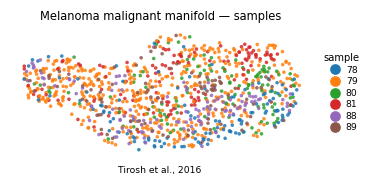

In [14]:
# save sample-integration figure on the house linear layout (single panel + external legend)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xy = plot.obsm['X_umap']
xlo,xhi = np.percentile(xy[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xy[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=22, alpha=.85, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.28, fontsize=6, title='sample', title_fontsize=6.5)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Melanoma malignant manifold \u2014 samples', size=7.5)
ax.text(.5, -.13, 'Tirosh et al., 2016', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', adata.shape[0])